# M115 — TP2 : Préparation et qualité des sources --> Binôme avec *Meriem Nassih*
## UCI Online Retail 

**Objectif :** Les principaux objectifs sont :

1. Charger les données et assurer leur traçabilité.
2. Réaliser un audit initial de la qualité des données.
3. Identifier et isoler les doublons exacts.
4. Normaliser les champs et contrôler les types.
5. Classifier les lignes selon un référentiel commun.
6. Identifier les motifs d'exclusion.
7. Appliquer les filtres successifs et construire un journal.
8. Vérifier la cohérence et la conservation des lignes.
9. Exporter les données préparées et les fichiers d'audit.

## 1. Importation des bibliothèques et chargement des données


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Recherche automatique du fichier dans les entrées Kaggle
candidates = list(Path("/kaggle/input").rglob("Online Retail.xlsx"))
if not candidates:
    # Utile si le fichier est placé manuellement dans le répertoire courant
    candidates = list(Path(".").rglob("Online Retail.xlsx"))

if not candidates:
    raise FileNotFoundError(
        "Online Retail.xlsx introuvable. Dans Kaggle, cliquez sur Add Input "
        "et ajoutez le dataset qui contient ce fichier."
    )

FILE_PATH = candidates[0]
print("Fichier chargé :", FILE_PATH)

df_raw = pd.read_excel(FILE_PATH)
df_raw.head()

Fichier chargé : /kaggle/input/datasets/nisrineqacem/online-retail/Online Retail.xlsx


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. État initial — profilage de la source

### — Pourquoi contrôler les données avant toute transformation ?

Le contrôle initial fournit une référence mesurable de la source brute. Il permet d'identifier les valeurs manquantes, les doublons exacts, les types de données et les valeurs atypiques avant toute modification. Les métriques initiales serviront ensuite à mesurer l'effet de chaque transformation et à justifier les décisions prises.

In [5]:
colonnes_attendues = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
]
colonnes_absentes = [c for c in colonnes_attendues if c not in df_raw.columns]
if colonnes_absentes:
    raise ValueError(f"Colonnes attendues absentes : {colonnes_absentes}")

profil_initial = pd.DataFrame({
    "Type": df_raw.dtypes.astype(str),
    "Valeurs_manquantes": df_raw.isna().sum(),
    "Pourcentage_manquant": (df_raw.isna().mean() * 100).round(2),
    "Valeurs_distinctes": df_raw.nunique(dropna=True)
})
print("Dimensions initiales (lignes, colonnes) :", df_raw.shape)
print("Doublons exacts initiaux :", int(df_raw.duplicated(subset=colonnes_attendues).sum()))
display(profil_initial)

print("\nStatistiques Quantity :")
display(df_raw["Quantity"].describe())
print("\nStatistiques UnitPrice :")
display(df_raw["UnitPrice"].describe())

print("\nMinimum Quantity :", df_raw["Quantity"].min())
print("Maximum Quantity :", df_raw["Quantity"].max())
print("Minimum UnitPrice :", df_raw["UnitPrice"].min())
print("Maximum UnitPrice :", df_raw["UnitPrice"].max())

Dimensions initiales (lignes, colonnes) : (541909, 8)
Doublons exacts initiaux : 5268


,Type,Valeurs_manquantes,Pourcentage_manquant,Valeurs_distinctes
InvoiceNo,object,0,0.00,25900
StockCode,object,0,0.00,4070
Description,object,1454,0.27,4223
Quantity,int64,0,0.00,722
InvoiceDate,datetime64[ns],0,0.00,23260
UnitPrice,float64,0,0.00,1630
CustomerID,float64,135080,24.93,4372
Country,object,0,0.00,38



Statistiques Quantity :


count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64


Statistiques UnitPrice :


count    541909.000000
mean          4.611114
std          96.759853
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64


Minimum Quantity : -80995
Maximum Quantity : 80995
Minimum UnitPrice : -11062.06
Maximum UnitPrice : 38970.0


### Réponse Markdown — Que constatez-vous et quel traitement appliquer ?

Les constats exacts doivent être formulés à partir des tableaux affichés ci-dessus. Les valeurs manquantes, les doublons, les quantités négatives ou nulles et les prix nuls ou négatifs doivent être mesurés et classés avant traitement. Une anomalie apparente n'est pas automatiquement une erreur : une quantité négative peut correspondre à un retour ou à une correction commerciale.

## 3. Questions de raisonnement

### 3.1 Quelles anomalies devez-vous mesurer avant de modifier les données ?

Il faut mesurer les valeurs manquantes par colonne, les doublons strictement identiques sur les huit colonnes métier, les factures dont le numéro commence par `C`, les quantités inférieures ou égales à zéro, les prix unitaires inférieurs ou égaux à zéro, les `CustomerID` manquants et les codes produits potentiellement non commerciaux. Ces mesures doivent être enregistrées avant le nettoyage.

### 3.2 Pourquoi `InvoiceNo` commençant par `C` ne doit-il pas être supprimé sans trace ?

Le préfixe `C` signale une annulation dans le périmètre de ce TP. Les annulations et retours sont exclus du périmètre de vente du MVP, mais doivent rester conservés dans la couche de staging/audit. Les supprimer sans trace ferait perdre une information métier et empêcherait de justifier les écarts entre la source brute et la source préparée.

### 3.3 Pourquoi `InvoiceNo + StockCode` ne constitue-t-il pas une clé de ligne ?

Une même facture peut contenir plusieurs lignes portant le même code produit, par exemple lorsque les lignes ont des caractéristiques ou des valeurs différentes. Dédupliquer avec seulement `InvoiceNo` et `StockCode` pourrait donc supprimer des lignes légitimes. Le TP impose de supprimer uniquement une copie lorsque les huit colonnes sources sont identiques.

### 3.4 Que faire d'un `CustomerID` manquant ?

Conserver la ligne et son information de vente pour un rattachement ultérieur à « Client inconnu ». L'absence de `CustomerID` ne suffit pas à supprimer une vente.

### 3.5 Comment distinguer un code non commercial d'un code commercial alphanumérique ?

La présence d'une lettre dans `StockCode` ne suffit pas pour exclure une ligne. La classification doit s'appuyer sur `StockCode`, `Description` et le comportement de la référence, selon la table de classification validée fournie avec le dossier. En l'absence de cette référence, les cas ambigus doivent être marqués `A_VERIFIER`, et non classés arbitrairement.

### 3.6 Quels contrôles prouvent l'effet des transformations ?

Comparer avant/après le nombre de lignes, les doublons exacts, les `CustomerID` manquants, les annulations/retours, les lignes avec `Quantity <= 0`, les lignes avec `UnitPrice <= 0`, les lignes non commerciales et la somme de `MontantLigne`. Il faut aussi conserver les lignes exclues dans une table d'audit et vérifier que les clients inconnus n'ont pas été supprimés abusivement.

## 4. Mesurer les anomalies

Le tableau suivant compte les principales classes de lignes. Les classes peuvent se chevaucher : une même ligne peut, par exemple, avoir une quantité négative et un numéro de facture commençant par `C`. Il ne faut donc pas additionner ces compteurs pour déduire le nombre total de lignes uniques à exclure.

In [6]:
# Copie de travail pour les contrôles : les valeurs brutes sont conservées
df = df_raw.copy()

invoice_str = df["InvoiceNo"].astype("string").str.strip()
mask_annulation = invoice_str.str.upper().str.startswith("C", na=False)
mask_qte_non_positive = pd.to_numeric(df["Quantity"], errors="coerce") <= 0
mask_prix_non_positive = pd.to_numeric(df["UnitPrice"], errors="coerce") <= 0
mask_client_manquant = df["CustomerID"].isna()
mask_doublon_exact = df.duplicated(subset=colonnes_attendues, keep="first")

anomalies = pd.DataFrame({
    "Phénomène": [
        "InvoiceNo commence par C",
        "Quantity <= 0",
        "UnitPrice <= 0",
        "CustomerID manquant",
        "Doublons exacts supplémentaires",
        "Description manquante",
        "StockCode manquant"
    ],
    "Nombre de lignes": [
        int(mask_annulation.sum()),
        int(mask_qte_non_positive.sum()),
        int(mask_prix_non_positive.sum()),
        int(mask_client_manquant.sum()),
        int(mask_doublon_exact.sum()),
        int(df["Description"].isna().sum()),
        int(df["StockCode"].isna().sum())
    ]
})
display(anomalies)

,Phénomène,Nombre de lignes
0,InvoiceNo commence par C,9288
1,Quantity <= 0,10624
2,UnitPrice <= 0,2517
3,CustomerID manquant,135080
4,Doublons exacts supplémentaires,5268
5,Description manquante,1454
6,StockCode manquant,0


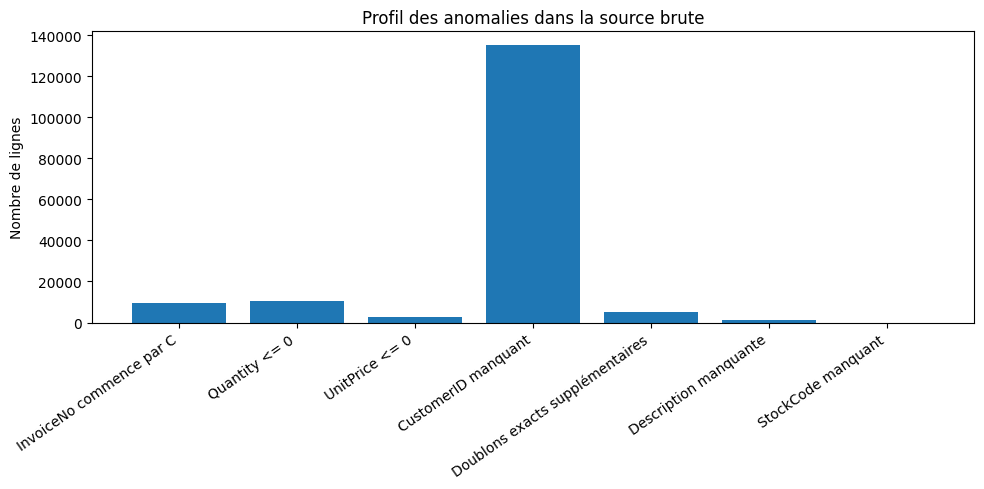

In [7]:
plt.figure(figsize=(10, 5))
plt.bar(anomalies["Phénomène"], anomalies["Nombre de lignes"])
plt.title("Profil des anomalies dans la source brute")
plt.ylabel("Nombre de lignes")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Question d'analyse — Une quantité négative est-elle nécessairement une erreur ? Quelle règle du MVP s'applique ?

Non. Une quantité négative peut correspondre à un retour ou à une annulation commerciale. Pour le périmètre `FactVente` du MVP, seules les lignes dont la facture n'est pas annulée, dont `Quantity > 0`, dont `UnitPrice > 0` et dont le type est `PRODUIT_COMMERCIAL` sont retenues. Les lignes écartées de ce périmètre restent traçables dans staging/audit.

## 5. Normaliser les champs texte sans inventer de valeurs

### Réponse Markdown — Pourquoi conserver les valeurs originales ?

Les valeurs originales permettent de justifier chaque correction, de comparer l'avant et l'après, de revenir à la donnée source et d'assurer la traçabilité. La normalisation ci-dessous retire uniquement les espaces en début et fin de texte (Trim). Elle ne crée aucune catégorie et ne remplace pas les valeurs manquantes.

In [8]:
df = df_raw.copy()

# Conserver les valeurs sources des champs concernés
for col in ["Description", "Country", "StockCode"]:
    df[f"{col}_Original"] = df[col]

# Normalisation textuelle : Trim uniquement, sans inventer de catégories
for col in ["Description", "Country", "StockCode"]:
    df[col] = df[col].map(lambda x: x.strip() if isinstance(x, str) else x)

display(
    df[["Description_Original", "Description", "Country_Original", "Country"]]
    .head(10)
)

,Description_Original,Description,Country_Original,Country
0,WHITE HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom,United Kingdom
1,WHITE METAL LANTERN,WHITE METAL LANTERN,United Kingdom,United Kingdom
2,CREAM CUPID HEARTS COAT HANGER,CREAM CUPID HEARTS COAT HANGER,United Kingdom,United Kingdom
3,KNITTED UNION FLAG HOT WATER BOTTLE,KNITTED UNION FLAG HOT WATER BOTTLE,United Kingdom,United Kingdom
4,RED WOOLLY HOTTIE WHITE HEART.,RED WOOLLY HOTTIE WHITE HEART.,United Kingdom,United Kingdom
5,SET 7 BABUSHKA NESTING BOXES,SET 7 BABUSHKA NESTING BOXES,United Kingdom,United Kingdom
6,GLASS STAR FROSTED T-LIGHT HOLDER,GLASS STAR FROSTED T-LIGHT HOLDER,United Kingdom,United Kingdom
7,HAND WARMER UNION JACK,HAND WARMER UNION JACK,United Kingdom,United Kingdom
8,HAND WARMER RED POLKA DOT,HAND WARMER RED POLKA DOT,United Kingdom,United Kingdom
9,ASSORTED COLOUR BIRD ORNAMENT,ASSORTED COLOUR BIRD ORNAMENT,United Kingdom,United Kingdom


## 6. Dédoublonner exactement

### Réponse Markdown — Pourquoi deux lignes avec le même `InvoiceNo` et `StockCode` peuvent-elles être légitimes ?

Une facture peut contenir plusieurs lignes avec le même code article. D'autres colonnes, comme la quantité, le prix, la description ou la date, peuvent différer. Le TP impose donc de considérer un doublon uniquement si les huit colonnes métier sont identiques. Une seule occurrence est conservée et le nombre de copies retirées est enregistré.

In [9]:
# Dédoublonnage sur les huit colonnes sources, et non sur deux colonnes seulement
nb_lignes_avant_dedoublonnage = len(df)
mask_copie_exacte = df.duplicated(subset=colonnes_attendues, keep="first")
doublons_exacts_audites = df.loc[mask_copie_exacte].copy()
df_dedup = df.drop_duplicates(subset=colonnes_attendues, keep="first").copy()
nb_doublons_retires = nb_lignes_avant_dedoublonnage - len(df_dedup)

print("Lignes avant :", nb_lignes_avant_dedoublonnage)
print("Copies exactes retirées :", nb_doublons_retires)
print("Lignes après :", len(df_dedup))
print("Doublons exacts restants :", int(df_dedup.duplicated(subset=colonnes_attendues).sum()))

Lignes avant : 541909
Copies exactes retirées : 5268
Lignes après : 536641
Doublons exacts restants : 0


## 7. Classification des lignes — étape dépendante de la référence validée

Le TP demande une classification explicite basée sur `StockCode + Description + comportement`, avec les catégories prévues par la référence du dossier, notamment `PRODUIT_COMMERCIAL` et `A_VERIFIER`. **Ne pas décider qu'un code est non commercial uniquement parce qu'il contient une lettre.**

Ajoutez le fichier de référence de classification (et les règles D01–D12 si elles sont dans un fichier séparé) à Kaggle. Le code ci-dessous recherche un fichier CSV ou Excel dont le nom contient `classification` ou `reference`. Vérifiez les colonnes de ce fichier et adaptez le rapprochement si leurs noms diffèrent.

In [10]:
# Recherche d'un éventuel fichier de référence de classification dans les entrées Kaggle
reference_files = []
for p in Path("/kaggle/input").rglob("*"):
    if p.is_file() and p.suffix.lower() in [".csv", ".xlsx", ".xls"]:
        nom = p.name.lower()
        if "classification" in nom or "reference" in nom or "référence" in nom:
            reference_files.append(p)

print("Fichiers de référence détectés :")
for p in reference_files:
    print("-", p)

# Par défaut, ne pas inventer la classification.
df_dedup["TypeLigne"] = "A_VERIFIER"
df_dedup["InclureFactVente"] = False

if reference_files:
    ref_path = reference_files[0]
    if ref_path.suffix.lower() == ".csv":
        ref = pd.read_csv(ref_path)
    else:
        ref = pd.read_excel(ref_path)
    print("\nFichier de référence sélectionné :", ref_path)
    print("Colonnes de la référence :", ref.columns.tolist())
    display(ref.head())
    print(
        "\nVérifiez les noms des colonnes de la référence, puis ajoutez le "
        "rapprochement StockCode + Description et les règles de comportement "
        "conformément au document validé avant de poursuivre."
    )
else:
    print(
        "Aucune référence détectée. Les lignes restent A_VERIFIER : "
        "ajoutez la référence fournie par le professeur pour produire "
        "une classification fiable."
    )

Fichiers de référence détectés :
Aucune référence détectée. Les lignes restent A_VERIFIER : ajoutez la référence fournie par le professeur pour produire une classification fiable.


### Réponse Markdown — Pourquoi une lettre dans `StockCode` ne suffit-elle pas à exclure une ligne ?

Un code alphanumérique peut être un code commercial valide. L'exclusion doit être basée sur la référence de classification validée, la description et le comportement de la ligne. Les cas ambigus doivent rester documentés comme `A_VERIFIER` jusqu'à validation.

## 8. Construire la source préparée L2

Le périmètre de vente du MVP est : facture non annulée, `Quantity > 0`, `UnitPrice > 0` et `TypeLigne = PRODUIT_COMMERCIAL`. Les lignes exclues sont conservées séparément pour audit. Si la classification n'a pas été chargée et validée, la source de ventes finales ne doit pas être présentée comme définitive.

In [11]:
# Copie d'audit : lignes écartées par les règles du périmètre
invoice_str_dedup = df_dedup["InvoiceNo"].astype("string").str.strip()
mask_invoice_non_annulee = ~invoice_str_dedup.str.upper().str.startswith("C", na=False)
mask_qte_positive = pd.to_numeric(df_dedup["Quantity"], errors="coerce") > 0
mask_prix_positif = pd.to_numeric(df_dedup["UnitPrice"], errors="coerce") > 0
mask_produit_commercial = df_dedup["TypeLigne"].eq("PRODUIT_COMMERCIAL")

mask_factvente = (
    mask_invoice_non_annulee
    & mask_qte_positive
    & mask_prix_positif
    & mask_produit_commercial
)

df_audit_exclusions = df_dedup.loc[~mask_factvente].copy()
df_l2 = df_dedup.loc[mask_factvente].copy()

# Montant dérivé uniquement dans la couche préparée
df_l2["MontantLigne"] = (
    pd.to_numeric(df_l2["Quantity"], errors="coerce")
    * pd.to_numeric(df_l2["UnitPrice"], errors="coerce")
)

print("Lignes après dédoublonnage :", len(df_dedup))
print("Lignes retenues dans la source de ventes préparée :", len(df_l2))
print("Lignes conservées en audit hors périmètre :", len(df_audit_exclusions))
print("Montant total MontantLigne :", df_l2["MontantLigne"].sum())

Lignes après dédoublonnage : 536641
Lignes retenues dans la source de ventes préparée : 0
Lignes conservées en audit hors périmètre : 536641
Montant total MontantLigne : 0.0


### Réponse Markdown — Quelle différence entre « exclue de FactVente » et « supprimée de la source » ?

Une ligne exclue de `FactVente` ne fait pas partie du périmètre de ventes retenu pour le modèle décisionnel, mais elle reste disponible dans la couche staging/audit avec la raison de son exclusion. Une ligne supprimée de la source n'est plus disponible pour les contrôles et la traçabilité. Dans ce TP, les annulations, retours et autres lignes hors périmètre doivent rester traçables.

## 9. Contrôles avant/après

Les métriques sont calculées automatiquement. Les compteurs des différentes anomalies ne sont pas nécessairement exclusifs : une même ligne peut satisfaire plusieurs conditions.

In [12]:
def indicateurs(data, nom):
    inv = data["InvoiceNo"].astype("string").str.strip()
    q = pd.to_numeric(data["Quantity"], errors="coerce")
    p = pd.to_numeric(data["UnitPrice"], errors="coerce")
    montant = q * p
    return {
        "Étape": nom,
        "Nombre de lignes": len(data),
        "Doublons exacts": int(data.duplicated(subset=colonnes_attendues).sum()),
        "CustomerID manquant": int(data["CustomerID"].isna().sum()),
        "Facture commençant par C": int(inv.str.upper().str.startswith("C", na=False).sum()),
        "Quantity <= 0": int((q <= 0).sum()),
        "UnitPrice <= 0": int((p <= 0).sum()),
        "TypeLigne non commercial / à vérifier": int((~data["TypeLigne"].eq("PRODUIT_COMMERCIAL")).sum())
            if "TypeLigne" in data.columns else np.nan,
        "Somme Quantity × UnitPrice": float(montant.sum(skipna=True))
    }

controle = pd.DataFrame([
    indicateurs(df_raw.assign(TypeLigne="A_VERIFIER"), "Source brute"),
    indicateurs(df_dedup, "Après dédoublonnage"),
    indicateurs(df_l2, "Source L2 ventes")
])
display(controle)

,Étape,Nombre de lignes,Doublons exacts,CustomerID manquant,Facture commençant par C,Quantity <= 0,UnitPrice <= 0,TypeLigne non commercial / à vérifier,Somme Quantity × UnitPrice
0,Source brute,541909,5268,135080,9288,10624,2517,541909,9747747.934
1,Après dédoublonnage,536641,0,135037,9251,10587,2512,536641,9726006.954
2,Source L2 ventes,0,0,0,0,0,0,0,0.000


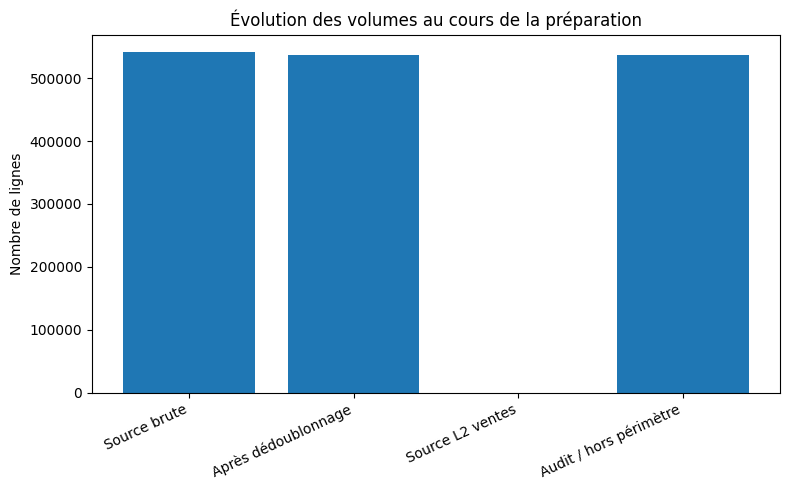

,Étape,Nombre de lignes
0,Source brute,541909
1,Après dédoublonnage,536641
2,Source L2 ventes,0
3,Audit / hors périmètre,536641


In [13]:
# Visualisation de l'évolution du nombre de lignes à chaque étape
etapes = pd.DataFrame({
    "Étape": ["Source brute", "Après dédoublonnage", "Source L2 ventes", "Audit / hors périmètre"],
    "Nombre de lignes": [len(df_raw), len(df_dedup), len(df_l2), len(df_audit_exclusions)]
})
plt.figure(figsize=(8, 5))
plt.bar(etapes["Étape"], etapes["Nombre de lignes"])
plt.title("Évolution des volumes au cours de la préparation")
plt.ylabel("Nombre de lignes")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()
display(etapes)

## 10. Défi technique — vérifier que les clients inconnus n'ont pas été supprimés

Le contrôle ne doit pas dépendre d'un nombre saisi manuellement. Il compare les identifiants de lignes techniques attribués à la source brute et à la source préparée. Les identifiants servent uniquement à l'audit du notebook, pas à créer une clé métier ou une clé de substitution du modèle.

In [14]:
# Repartir de la source brute en ajoutant un identifiant technique temporaire d'audit
raw_audit = df_raw.copy().reset_index(drop=True)
raw_audit["_audit_row_id"] = np.arange(len(raw_audit))

# Associer l'identifiant aux lignes préparées via les huit colonnes source.
# En présence de doublons exacts, une occurrence est conservée : on utilise
# cumcount pour associer les occurrences sans confondre deux lignes identiques.
keys = colonnes_attendues
raw_audit["_occurrence"] = raw_audit.groupby(keys, dropna=False).cumcount()
dedup_for_check = raw_audit.drop_duplicates(subset=keys, keep="first").copy()

# Contrôle dynamique : chaque ligne brute avec CustomerID manquant doit être
# soit présente dans la source préparée, soit explicitement conservée dans l'audit.
missing_customer_raw = raw_audit[raw_audit["CustomerID"].isna()]
missing_customer_kept = (
    df_dedup["CustomerID"].isna().sum()
    + df_audit_exclusions["CustomerID"].isna().sum()
)

# Après dédoublonnage, le nombre de clients manquants doit être retrouvé
# dans les lignes dédoublonnées (les copies exactes retirées sont auditées à part).
missing_customer_after_dedup = int(df_dedup["CustomerID"].isna().sum())
missing_customer_raw_unique = int(
    raw_audit.drop_duplicates(subset=keys, keep="first")["CustomerID"].isna().sum()
)

if missing_customer_after_dedup != missing_customer_raw_unique:
    print("ERREUR : des lignes avec CustomerID manquant ont été perdues au dédoublonnage.")
else:
    print("Contrôle OK : les lignes uniques avec CustomerID manquant sont conservées après dédoublonnage.")

print("Lignes brutes avec CustomerID manquant :", int(missing_customer_raw.shape[0]))
print("Lignes uniques avec CustomerID manquant :", missing_customer_raw_unique)
print("Lignes avec CustomerID manquant après dédoublonnage :", missing_customer_after_dedup)

Contrôle OK : les lignes uniques avec CustomerID manquant sont conservées après dédoublonnage.
Lignes brutes avec CustomerID manquant : 135080
Lignes uniques avec CustomerID manquant : 135037
Lignes avec CustomerID manquant après dédoublonnage : 135037


## 11. Interprétation finale

### Quels changements sont mesurés et pourquoi ?

Les changements sont mesurés par les écarts de lignes, de doublons exacts, de clients inconnus, d'annulations/retours, de quantités et prix non positifs, de classification des lignes et de montant calculé. Ils proviennent des règles de dédoublonnage et du périmètre de vente du MVP. Les valeurs exactes doivent être commentées à partir des tableaux produits par le notebook.

### Quelle version de L2 transmettre à TP3 ?

Transmettre la source préparée avec les lignes validées pour le périmètre de vente, la couche d'audit contenant les lignes hors périmètre, les doublons exacts retirés et leurs compteurs, la traçabilité des transformations et le rapport de contrôles avant/après. Les catégories non validées ne doivent pas être inventées. Ce TP ne demande pas de créer les dimensions, les clés de substitution ni la table `FactVente` : ces éléments sont réservés à TP3.

## 12. Export des livrables

Les fichiers seront enregistrés dans `/kaggle/working`, puis pourront être téléchargés depuis l'onglet Output du notebook Kaggle.

In [15]:
from pathlib import Path

out_dir = Path("/kaggle/working")
out_dir.mkdir(parents=True, exist_ok=True)

df_l2.to_csv(out_dir / "L2_ventes_preparees.csv", index=False, encoding="utf-8-sig")
df_audit_exclusions.to_csv(out_dir / "L2_audit_exclusions.csv", index=False, encoding="utf-8-sig")
doublons_exacts_audites.to_csv(out_dir / "doublons_exacts_retires.csv", index=False, encoding="utf-8-sig")
controle.to_csv(out_dir / "rapport_controles_qualite.csv", index=False, encoding="utf-8-sig")
anomalies.to_csv(out_dir / "rapport_anomalies_initiales.csv", index=False, encoding="utf-8-sig")

print("Fichiers exportés :")
for p in sorted(out_dir.glob("*.csv")):
    print(p.name, "-", p.stat().st_size, "octets")

Fichiers exportés :
L2_audit_exclusions.csv - 82352842 octets
L2_ventes_preparees.csv - 182 octets
doublons_exacts_retires.csv - 738420 octets
rapport_anomalies_initiales.csv - 215 octets
rapport_controles_qualite.csv - 373 octets


## Conclusion générale

La préparation de la source consiste à mesurer la qualité des données, à normaliser les champs texte sans altérer leur sens, à retirer uniquement les doublons exacts, à appliquer les règles métier validées et à conserver les lignes exclues dans une couche d'audit. La traçabilité des transformations permet de justifier les différences entre la source brute et L2. La classification définitive des produits dépend de la référence validée fournie avec le TP.